In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from sklearn.calibration import (
    calibration_curve,
    CalibratedClassifierCV
)

In [2]:
prediction_dir = Path(
    "../../../data/processed/model_predictions"
)

prediction_files = {
    "Logistic Regression": "combined_model_predictions.csv",
    "Random Forest": "random_forest_predictions.csv",
    "XGBoost": "xgboost_predictions.csv",
    "LightGBM": "lightgbm_predictions.csv"
}

model_predictions = {}

for model_name, filename in prediction_files.items():

    predictions = pd.read_csv(prediction_dir / filename)

    model_predictions[model_name] = predictions

    print(
        f"{model_name}: "
        f"{predictions.shape}, "
        f"duplicates = "
        f"{predictions.duplicated(['user_id', 'order_id']).sum()}"
    )

Logistic Regression: (219983, 5), duplicates = 0
Random Forest: (219983, 5), duplicates = 0
XGBoost: (219983, 5), duplicates = 0
LightGBM: (219983, 5), duplicates = 0


In [3]:
reference_name = "Logistic Regression"
reference = model_predictions[reference_name]

key_columns = ["user_id", "order_id"]

for model_name, predictions in model_predictions.items():

    # Check that every model predicts the same interactions
    same_keys = (
        predictions[key_columns]
        .sort_values(key_columns)
        .reset_index(drop=True)
        .equals(
            reference[key_columns]
            .sort_values(key_columns)
            .reset_index(drop=True)
        )
    )

    # Check that actual labels are identical
    same_labels = (
        predictions
        .set_index(key_columns)["y_true"]
        .sort_index()
        .equals(
            reference
            .set_index(key_columns)["y_true"]
            .sort_index()
        )
    )

    print(
        f"{model_name}: "
        f"Same interactions = {same_keys}, "
        f"Same labels = {same_labels}"
    )

Logistic Regression: Same interactions = True, Same labels = True
Random Forest: Same interactions = True, Same labels = True
XGBoost: Same interactions = True, Same labels = True
LightGBM: Same interactions = True, Same labels = True


In [4]:
for model_name, predictions in model_predictions.items():
    print(f"\n{model_name}")
    print("Columns:", predictions.columns.tolist())
    print(predictions.head(3))


Logistic Regression
Columns: ['user_id', 'order_id', 'fold', 'y_true', 'y_pred_proba']
   user_id  order_id  fold  y_true  y_pred_proba
0    21825  21616385     1       0      0.600080
1    21825  21616478     1       1      0.510622
2    21825  21616677     1       1      0.628466

Random Forest
Columns: ['user_id', 'order_id', 'fold', 'y_true', 'y_pred_proba']
   user_id  order_id  fold  y_true  y_pred_proba
0    21825  21616385     1       0      0.446022
1    21825  21616478     1       1      0.507211
2    21825  21616677     1       1      0.581992

XGBoost
Columns: ['user_id', 'order_id', 'fold', 'y_true', 'y_pred_proba']
   user_id  order_id  fold  y_true  y_pred_proba
0    21825  21616385     1       0      0.400498
1    21825  21616478     1       1      0.441136
2    21825  21616677     1       1      0.546249

LightGBM
Columns: ['user_id', 'order_id', 'fold', 'y_true', 'y_pred_proba']
   user_id  order_id  fold  y_true  y_pred_proba
0    21825  21616385     1       0      

In [5]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss
)

evaluation_data = {}

for model_name, predictions in model_predictions.items():

    y_risk = 1 - predictions["y_true"].to_numpy()
    risk_proba = 1 - predictions["y_pred_proba"].to_numpy()

    evaluation_data[model_name] = {
        "y_true": y_risk,
        "y_proba": risk_proba,
        "fold": predictions["fold"].to_numpy()
    }

    print(
        f"{model_name}: "
        f"Risk prevalence = {y_risk.mean():.4f}, "
        f"Probability range = "
        f"({risk_proba.min():.4f}, {risk_proba.max():.4f})"
    )

Logistic Regression: Risk prevalence = 0.3414, Probability range = (0.0165, 0.9872)
Random Forest: Risk prevalence = 0.3414, Probability range = (0.0373, 0.9859)
XGBoost: Risk prevalence = 0.3414, Probability range = (0.0282, 0.9939)
LightGBM: Risk prevalence = 0.3414, Probability range = (0.0367, 0.9874)


In [8]:
from sklearn.dummy import DummyClassifier

# Fit the baseline using the training labels from the OOF dataset.
# This classifier always predicts the majority class.
baseline_model = DummyClassifier(strategy="prior")

baseline_model.fit(
    np.zeros((len(evaluation_data["XGBoost"]["y_true"]), 1)),
    evaluation_data["XGBoost"]["y_true"]
)

baseline_risk_proba = baseline_model.predict_proba(
    np.zeros((len(evaluation_data["XGBoost"]["y_true"]), 1))
)[:, 1]

print("Baseline risk probability:", baseline_risk_proba[0])

Baseline risk probability: 0.3413763790838383


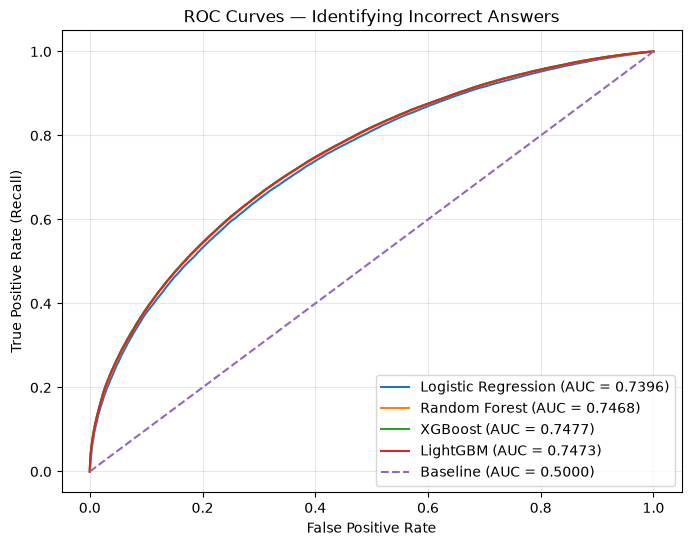

In [9]:
plt.figure(figsize=(8, 6))

for model_name, data in evaluation_data.items():
    fpr, tpr, _ = roc_curve(data["y_true"], data["y_proba"])
    auc = roc_auc_score(data["y_true"], data["y_proba"])

    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.4f})")

# Baseline ROC
baseline_fpr, baseline_tpr, _ = roc_curve(
    evaluation_data["XGBoost"]["y_true"],
    baseline_risk_proba
)

baseline_auc = roc_auc_score(
    evaluation_data["XGBoost"]["y_true"],
    baseline_risk_proba
)

plt.plot(
    baseline_fpr,
    baseline_tpr,
    linestyle="--",
    label=f"Baseline (AUC = {baseline_auc:.4f})"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Identifying Incorrect Answers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

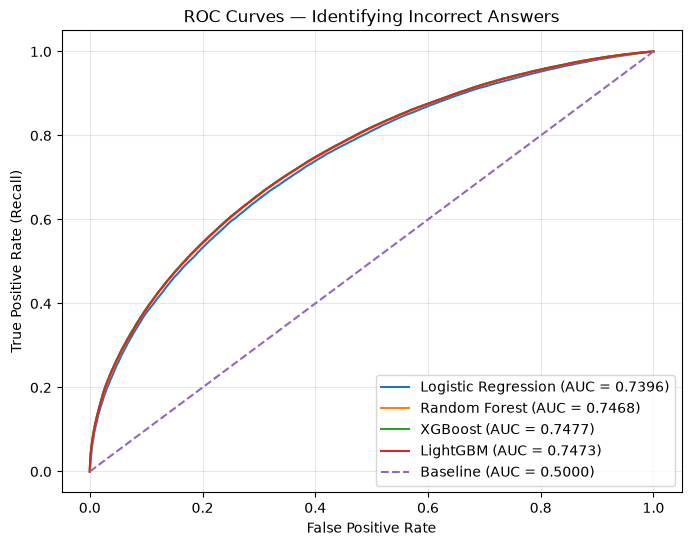

In [11]:
plt.figure(figsize=(8, 6))

for model_name, data in evaluation_data.items():
    fpr, tpr, _ = roc_curve(data["y_true"], data["y_proba"])
    auc = roc_auc_score(data["y_true"], data["y_proba"])

    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.4f})")

# Baseline ROC
baseline_fpr, baseline_tpr, _ = roc_curve(
    evaluation_data["XGBoost"]["y_true"],
    baseline_risk_proba
)

baseline_auc = roc_auc_score(
    evaluation_data["XGBoost"]["y_true"],
    baseline_risk_proba
)

plt.plot(
    baseline_fpr,
    baseline_tpr,
    linestyle="--",
    label=f"Baseline (AUC = {baseline_auc:.4f})"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves — Identifying Incorrect Answers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

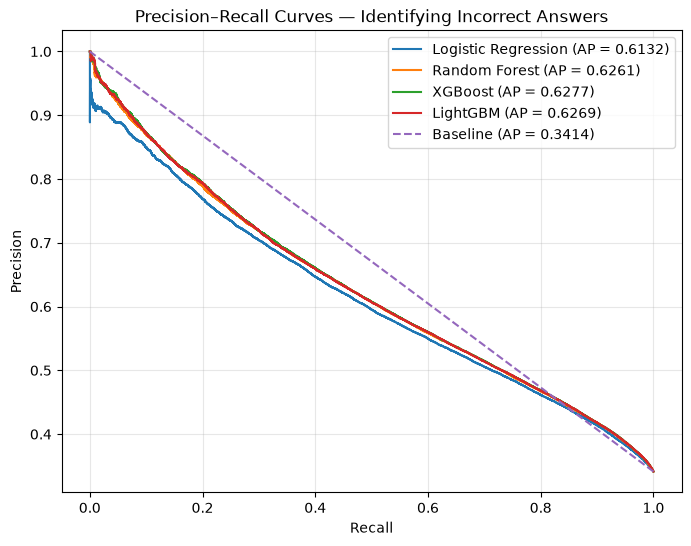

In [10]:
plt.figure(figsize=(8, 6))

for model_name, data in evaluation_data.items():
    precision, recall, _ = precision_recall_curve(
        data["y_true"], data["y_proba"]
    )

    ap = average_precision_score(data["y_true"], data["y_proba"])

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap:.4f})"
    )

# Baseline PR
baseline_precision, baseline_recall, _ = precision_recall_curve(
    evaluation_data["XGBoost"]["y_true"],
    baseline_risk_proba
)

baseline_ap = average_precision_score(
    evaluation_data["XGBoost"]["y_true"],
    baseline_risk_proba
)

plt.plot(
    baseline_recall,
    baseline_precision,
    linestyle="--",
    label=f"Baseline (AP = {baseline_ap:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — Identifying Incorrect Answers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

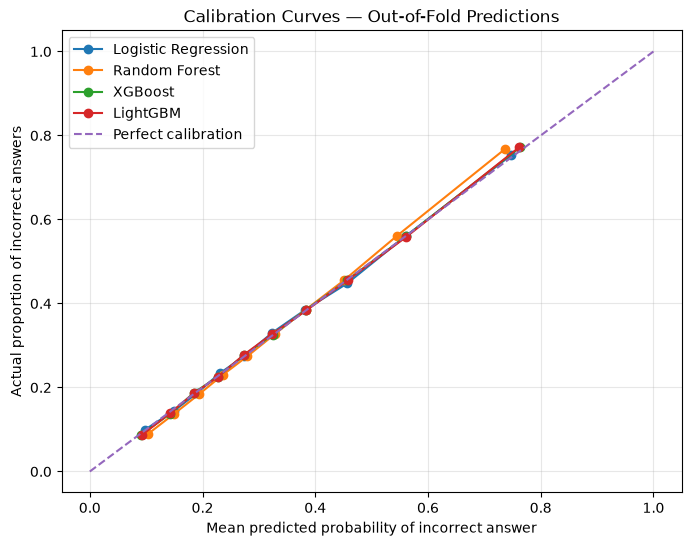

In [12]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

for model_name, data in evaluation_data.items():

    actual_rate, predicted_rate = calibration_curve(
        data["y_true"],
        data["y_proba"],
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        predicted_rate,
        actual_rate,
        marker="o",
        label=model_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability of incorrect answer")
plt.ylabel("Actual proportion of incorrect answers")
plt.title("Calibration Curves — Out-of-Fold Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
from sklearn.metrics import precision_recall_curve, confusion_matrix

TARGET_RECALL = 0.90

threshold_results = []

for model_name, data in evaluation_data.items():

    y_true = data["y_true"]
    y_proba = data["y_proba"]

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        y_proba
    )

    # The final precision/recall point has no corresponding threshold.
    valid = recall[:-1] >= TARGET_RECALL

    if not valid.any():
        print(f"{model_name}: Cannot achieve {TARGET_RECALL:.0%} recall")
        continue

    # Find the highest precision among thresholds satisfying our recall target.
    valid_indices = np.where(valid)[0]
    best_index = valid_indices[
        np.argmax(precision[:-1][valid])
    ]

    threshold = thresholds[best_index]

    # Predictions using the selected threshold
    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Recall": tp / (tp + fn),
        "Precision": tp / (tp + fp),
        "Specificity": tn / (tn + fp),
        "False Positive Rate": fp / (fp + tn),
        "Flagged Interactions": tp + fp,
        "False Alarms": fp
    })

threshold_summary = (
    pd.DataFrame(threshold_results)
    .sort_values("Precision", ascending=False)
    .reset_index(drop=True)
)

display(threshold_summary.round(4))

,Model,Threshold,Recall,Precision,Specificity,False Positive Rate,Flagged Interactions,False Alarms
0,LightGBM,0.1919,0.9,0.4179,0.3503,0.6497,161721,94133
1,Random Forest,0.2005,0.9,0.4178,0.3500,0.6500,161764,94175
2,XGBoost,0.1914,0.9,0.4177,0.3497,0.6503,161803,94214
3,Logistic Regression,0.1923,0.9,0.4136,0.3385,0.6615,163427,95836


In [14]:
recall_targets = [0.80, 0.85, 0.90]

sensitivity_results = []

for model_name, data in evaluation_data.items():

    y_true = data["y_true"]
    y_proba = data["y_proba"]

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_proba
    )

    for target in recall_targets:

        valid_indices = np.where(recall[:-1] >= target)[0]

        if len(valid_indices) == 0:
            continue

        best_index = valid_indices[
            np.argmax(precision[valid_indices])
        ]

        threshold = thresholds[best_index]

        y_pred = (y_proba >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        sensitivity_results.append({
            "Model": model_name,
            "Target Recall": target,
            "Threshold": threshold,
            "Actual Recall": tp / (tp + fn),
            "Precision": tp / (tp + fp),
            "Specificity": tn / (tn + fp),
            "False Alarms": fp,
            "Flagged Interactions": tp + fp
        })

sensitivity_summary = pd.DataFrame(sensitivity_results)

display(
    sensitivity_summary
    .sort_values(["Target Recall", "Precision"],
                 ascending=[True, False])
    .round(4)
)

,Model,Target Recall,Threshold,Actual Recall,Precision,Specificity,False Alarms,Flagged Interactions
6,XGBoost,0.80,0.2580,0.8000,0.4686,0.5299,68116,128194
9,LightGBM,0.80,0.2571,0.8000,0.4682,0.5290,68242,128322
3,Random Forest,0.80,0.2641,0.8000,0.4674,0.5275,68454,128532
0,Logistic Regression,0.80,0.2550,0.8000,0.4615,0.5162,70103,130181
10,LightGBM,0.85,0.2264,0.8500,0.4446,0.4497,79733,143568
7,XGBoost,0.85,0.2265,0.8500,0.4444,0.4493,79794,143627
4,Random Forest,0.85,0.2341,0.8501,0.4430,0.4460,80266,144106
1,Logistic Regression,0.85,0.2255,0.8500,0.4392,0.4375,81502,145335
11,LightGBM,0.90,0.1919,0.9000,0.4179,0.3503,94133,161721
5,Random Forest,0.90,0.2005,0.9000,0.4178,0.3500,94175,161764


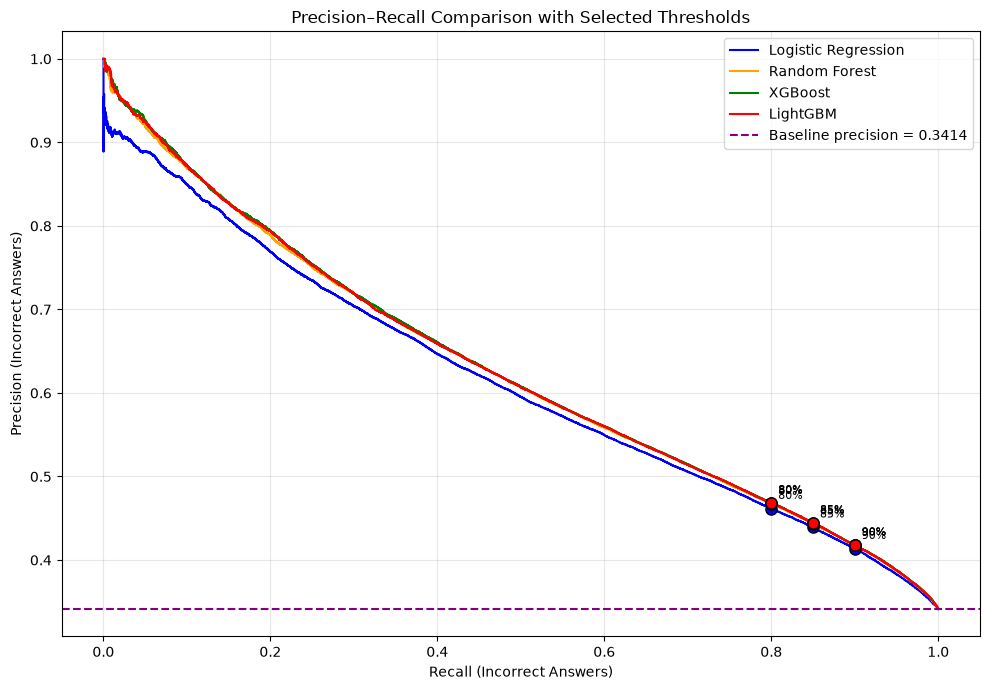

In [15]:
plt.figure(figsize=(10, 7))

colors = {
    "Logistic Regression": "blue",
    "Random Forest": "orange",
    "XGBoost": "green",
    "LightGBM": "red"
}

for model_name, data in evaluation_data.items():

    precision, recall, thresholds = precision_recall_curve(
        data["y_true"],
        data["y_proba"]
    )

    # Plot the complete PR curve
    plt.plot(
        recall,
        precision,
        label=model_name,
        color=colors[model_name]
    )

    # Mark the selected operating points
    model_points = sensitivity_summary[
        sensitivity_summary["Model"] == model_name
    ]

    plt.scatter(
        model_points["Actual Recall"],
        model_points["Precision"],
        color=colors[model_name],
        edgecolors="black",
        s=65,
        zorder=5
    )

    # Annotate each operating point
    for _, point in model_points.iterrows():
        plt.annotate(
            f'{point["Target Recall"]:.0%}',
            (
                point["Actual Recall"],
                point["Precision"]
            ),
            xytext=(5, 7),
            textcoords="offset points",
            fontsize=8
        )

# Baseline precision
baseline = evaluation_data["XGBoost"]["y_true"].mean()

plt.axhline(
    baseline,
    linestyle="--",
    color="purple",
    label=f"Baseline precision = {baseline:.4f}"
)

plt.xlabel("Recall (Incorrect Answers)")
plt.ylabel("Precision (Incorrect Answers)")
plt.title("Precision–Recall Comparison with Selected Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
recall_targets = [0.65, 0.70, 0.75, 0.80]

lower_recall_results = []

for model_name, data in evaluation_data.items():

    y_true = data["y_true"]
    y_proba = data["y_proba"]

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_proba
    )

    for target in recall_targets:

        valid_indices = np.where(recall[:-1] >= target)[0]

        best_index = valid_indices[
            np.argmax(precision[valid_indices])
        ]

        threshold = thresholds[best_index]

        y_pred = (y_proba >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        lower_recall_results.append({
            "Model": model_name,
            "Target Recall": target,
            "Threshold": threshold,
            "Actual Recall": tp / (tp + fn),
            "Precision": tp / (tp + fp),
            "Specificity": tn / (tn + fp),
            "False Alarms": fp,
            "Flagged Interactions": tp + fp
        })

lower_recall_summary = pd.DataFrame(lower_recall_results)

display(
    lower_recall_summary
    .sort_values(
        ["Target Recall", "Precision"],
        ascending=[True, False]
    )
    .round(4)
)

,Model,Target Recall,Threshold,Actual Recall,Precision,Specificity,False Alarms,Flagged Interactions
8,XGBoost,0.65,0.3450,0.6500,0.5371,0.7097,42065,90881
4,Random Forest,0.65,0.3469,0.6501,0.5363,0.7087,42203,91022
12,LightGBM,0.65,0.3444,0.6500,0.5362,0.7086,42223,91038
0,Logistic Regression,0.65,0.3395,0.6500,0.5279,0.6987,43651,92466
9,XGBoost,0.70,0.3171,0.7000,0.5147,0.6579,49563,102131
5,Random Forest,0.70,0.3205,0.7000,0.5146,0.6578,49584,102152
13,LightGBM,0.70,0.3153,0.7000,0.5138,0.6567,49742,102310
1,Logistic Regression,0.70,0.3118,0.7000,0.5056,0.6453,51396,103966
14,LightGBM,0.75,0.2867,0.7500,0.4919,0.5984,58183,114508
10,XGBoost,0.75,0.2880,0.7500,0.4917,0.5981,58223,114546


In [17]:
selected_models = {
    "XGBoost": 0.2880,
    "LightGBM": 0.2867
}

fold_results = []

for model_name, threshold in selected_models.items():

    data = evaluation_data[model_name]

    y_true = data["y_true"]
    y_proba = data["y_proba"]
    folds = data["fold"]

    for fold_number in sorted(np.unique(folds)):

        # Select predictions belonging to this validation fold
        mask = folds == fold_number

        y_fold = y_true[mask]
        p_fold = y_proba[mask]

        # Apply the same selected threshold
        y_pred = (p_fold >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_fold,
            y_pred,
            labels=[0, 1]
        ).ravel()

        fold_results.append({
            "Model": model_name,
            "Fold": fold_number,
            "Threshold": threshold,
            "Recall": tp / (tp + fn),
            "Precision": tp / (tp + fp),
            "Specificity": tn / (tn + fp),
            "False Alarms": fp,
            "Total Interactions": len(y_fold)
        })

fold_summary = pd.DataFrame(fold_results)

display(fold_summary.round(4))

,Model,Fold,Threshold,Recall,Precision,Specificity,False Alarms,Total Interactions
0,XGBoost,1,0.2880,0.7617,0.5082,0.6071,10933,42659
1,XGBoost,2,0.2880,0.7420,0.4649,0.5893,12122,43710
2,XGBoost,3,0.2880,0.7635,0.4958,0.5666,13852,49797
3,XGBoost,4,0.2880,0.7355,0.4859,0.6046,10926,41672
4,XGBoost,5,0.2880,0.7430,0.5038,0.6284,10387,42145
5,LightGBM,1,0.2867,0.7623,0.5082,0.6068,10942,42659
6,LightGBM,2,0.2867,0.7408,0.4657,0.5912,12065,43710
7,LightGBM,3,0.2867,0.7641,0.4963,0.5672,13832,49797
8,LightGBM,4,0.2867,0.7364,0.4852,0.6030,10969,41672
9,LightGBM,5,0.2867,0.7426,0.5037,0.6283,10388,42145


In [18]:
fold_metrics_summary = (
    fold_summary
    .groupby("Model")
    .agg({
        "Recall": ["mean", "std"],
        "Precision": ["mean", "std"],
        "Specificity": ["mean", "std"]
    })
)

display(fold_metrics_summary.round(4))

Recall         Precision         Specificity        
            mean     std      mean     std        mean     std
Model                                                         
LightGBM  0.7492  0.0130    0.4918  0.0170      0.5993  0.0224
XGBoost   0.7492  0.0126    0.4917  0.0172      0.5992  0.0229